# Phase 6 — DIC and COFI on PySpark: Big-Data Performance
**Student:** Jeswin Tobias J &nbsp;|&nbsp; **Roll No:** CS23I1013
**Task:** test-drive two of the predictive techniques on PySpark and establish the performance gain from big-data support.

### Which two techniques, and why
| Technique | Parallel structure | Chosen |
|---|---|---|
| **DIC** | counting a block of M transactions is independent per row → split each block across cores | ✅ |
| **COFI** | each item's COFI-tree is independent of the others → one Spark task per item | ✅ |
| DIANA | each split depends on the previous one; data is only 364 days (1 MB) | ✗ (sequential, tiny) |

### How each runs on Spark (`src/spark_arm.py`)
- **Spark DIC** — the driver keeps the same DIC state machine as Phase 3 (`src/arm.dic`). Each station's block of M rows is stored as **P = 10 partitions**; `sc.runJob` counts all dashed itemsets on those partitions in parallel and sums the counts. Transactions are 64-bit item masks: *T ⊇ S ⇔ T & S = S*.
- **Spark COFI** — job 1: each partition merges its identical transactions (a **map-side combiner**, like SQL partial `GROUP BY`), then `reduceByKey` merges across partitions → ≈ 4 k (transaction, count) pairs; N and item supports follow on the driver. Shuffle: each weighted transaction emits, for each item *i*, the items more frequent than *i* (its FP-path); `groupByKey` gathers one COFI-tree's paths per task, mined with **exactly the Phase 5 code** (`mine_item`). The first, naive version (every record projected before merging, one extra Spark job) is kept for comparison (§4).

### Fair-comparison rules
- Both COFI versions merge identical transactions in one pass first (single-machine: `Counter`; Spark: per-partition combiner) → Spark gets no algorithmic shortcut the baseline lacks.
- Same algorithm code, same parameters (min support 10 %, M = 5,000 × scale), and **identical outputs checked at every scale**.
- **Bigger data** = the 52,416 transactions replicated k times (k = 1 … 40 → up to 2.1 M). Support fractions do not change, so the itemsets stay the same and every count is exactly k × the original — an exact correctness check.
- Times are for the **algorithm only** (data already in memory / cached in Spark), best of 2 runs. Spark start-up and data loading are reported separately.
- Hardware: one laptop, Spark `local[*]` (10 cores). A real cluster adds network cost but also more machines.

In [1]:
import sys, os, time, shutil, tempfile, warnings; sys.path.append('..')
os.environ['SPARK_LOCAL_IP'] = '127.0.0.1'          # bind locally (also silences hostname warnings)
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from src.common import *
from src.arm import encode, dic
from src.cofi import cofi
from src.spark_arm import masks_rdd, spark_dic, spark_cofi, spark_cofi_naive

set_style(); header()
MIN_SUP, M0 = 0.10, 5000
SRC_ZIP = shutil.make_archive(os.path.join(tempfile.mkdtemp(), 'src'), 'zip', '..', 'src')   # ship src/ to Spark workers

def start_spark(cores='*'):
    t0 = time.perf_counter()
    spark = (SparkSession.builder.master(f'local[{cores}]').appName('ASBD-CS23I1013')
             .config('spark.driver.memory', '6g').config('spark.ui.enabled', 'false')
             .config('spark.ui.showConsoleProgress', 'false').getOrCreate())
    spark.sparkContext.setLogLevel('ERROR'); spark.sparkContext.addPyFile(SRC_ZIP)
    return spark, time.perf_counter() - t0

def best_of(f, runs=2):
    out, best = None, np.inf
    for _ in range(runs):
        t0 = time.perf_counter(); out = f(); best = min(best, time.perf_counter() - t0)
    return out, best

spark, t_start = start_spark()
sc = spark.sparkContext
print(f'Spark {spark.version} | cores = {sc.defaultParallelism} | start-up = {t_start:.1f} s')

Jeswin Tobias J | CS23I1013 | ASBD Hackathon — Tetouan Power Consumption


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/21 14:23:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0 | cores = 10 | start-up = 2.7 s


## 1. Data

In [2]:
T = [line.split(',') for line in (OUTPUTS / 'transactions.txt').read_text().splitlines()]
X, items = encode(T)
idx = {it: k for k, it in enumerate(items)}
T_ids = [[idx[i] for i in t] for t in T]                 # item ids: smaller to ship than strings
N0, I = X.shape
print(f'{N0} transactions, {I} items; one transaction = one 64-bit mask, e.g. {int((X[0] * (1 << np.arange(I))).sum()):#x}')

52416 transactions, 35 items; one transaction = one 64-bit mask, e.g. 0x151510548


## 2. Correctness at 1× — Spark output = single-machine output

In [3]:
P = sc.defaultParallelism
rdd, n_blocks = masks_rdd(sc, X, M0, P)
f_py_dic, _, s_py_dic = dic(X, MIN_SUP, M0)
f_sp_dic, _, s_sp_dic = spark_dic(sc, rdd, N0, I, MIN_SUP, M0, P)
rdd.unpersist()
print(f'DIC : {len(f_sp_dic)} itemsets | identical to Python DIC: {f_sp_dic == f_py_dic} | passes {s_sp_dic["passes"]:.2f} | '
      f'{n_blocks} blocks x {P} partitions')

f_py_cofi, _, _ = cofi(T_ids, MIN_SUP)
trdd = sc.parallelize(T_ids, 2 * P).cache(); trdd.count()
f_sp_cofi, _ = spark_cofi(sc, trdd, MIN_SUP)
trdd.unpersist()
print(f'COFI: {len(f_sp_cofi)} itemsets | identical to Python COFI: {f_sp_cofi == f_py_cofi}')
print('DIC and COFI agree with each other:', {frozenset(s) for s in f_py_dic} == set(f_py_cofi))

DIC : 768 itemsets | identical to Python DIC: True | passes 5.57 | 11 blocks x 10 partitions


COFI: 768 itemsets | identical to Python COFI: True
DIC and COFI agree with each other: True


**Inference:** both distributed versions return **exactly the same 768 itemsets and counts** as the single-machine code (and DIC needs the same 5.57 passes). DIC and COFI also agree with each other → the Spark speed-ups below compare equal work.

## 3. Scaling study — 1× to 40× the data

In [4]:
SCALES = [1, 5, 10, 20, 40]
base_dic = {s: c for s, c in f_py_dic.items()}
base_cofi = dict(f_py_cofi)
rows = []
for k in SCALES:
    Xk, Tk, Mk = np.tile(X, (k, 1)), T_ids * k, M0 * k
    Nk = len(Xk)
    # --- DIC
    (f1, _, s1), t_py_dic = best_of(lambda: dic(Xk, MIN_SUP, Mk))
    t0 = time.perf_counter(); rdd, _ = masks_rdd(sc, Xk, Mk, P); load_dic = time.perf_counter() - t0
    (f2, _, s2), t_sp_dic = best_of(lambda: spark_dic(sc, rdd, Nk, I, MIN_SUP, Mk, P))
    rdd.unpersist()
    # --- COFI
    (f3, _, _), t_py_cofi = best_of(lambda: cofi(Tk, MIN_SUP))
    t0 = time.perf_counter(); trdd = sc.parallelize(Tk, 2 * P).cache(); trdd.count(); load_cofi = time.perf_counter() - t0
    (f4, _), t_sp_cofi = best_of(lambda: spark_cofi(sc, trdd, MIN_SUP))
    trdd.unpersist()
    ok = (f1 == f2 == {s: c * k for s, c in base_dic.items()}) and (f3 == f4 == {s: c * k for s, c in base_cofi.items()})
    rows.append({'scale': k, 'transactions': Nk, 'DIC python': t_py_dic, 'DIC spark': t_sp_dic,
                 'COFI python': t_py_cofi, 'COFI spark': t_sp_cofi, 'spark load DIC': load_dic,
                 'spark load COFI': load_cofi, 'DIC passes': s1['passes'], 'results identical (counts = k x base)': ok})
    print(f'{k:>3}x  N={Nk:>9,}  DIC py {t_py_dic:6.2f}s  spark {t_sp_dic:6.2f}s | COFI py {t_py_cofi:6.2f}s  spark {t_sp_cofi:6.2f}s | ok={ok}')
res = pd.DataFrame(rows).set_index('scale')
res['DIC speed-up'] = res['DIC python'] / res['DIC spark']
res['COFI speed-up'] = res['COFI python'] / res['COFI spark']
res.to_csv(OUTPUTS / 'spark_scaling.csv')
res.round(2)

  1x  N=   52,416  DIC py   0.33s  spark   1.24s | COFI py   0.05s  spark   0.20s | ok=True


  5x  N=  262,080  DIC py   0.64s  spark   1.07s | COFI py   0.09s  spark   0.23s | ok=True


 10x  N=  524,160  DIC py   1.05s  spark   1.09s | COFI py   0.14s  spark   0.26s | ok=True


 20x  N=1,048,320  DIC py   1.92s  spark   1.20s | COFI py   0.25s  spark   0.32s | ok=True


 40x  N=2,096,640  DIC py   3.66s  spark   1.22s | COFI py   0.48s  spark   0.37s | ok=True


,transactions,DIC python,DIC spark,COFI python,COFI spark,spark load DIC,spark load COFI,DIC passes,results identical (counts = k x base),DIC speed-up,COFI speed-up
scale,,,,,,,,,,,
1,52416,0.33,1.24,0.05,0.20,0.30,0.04,5.57,True,0.26,0.23
5,262080,0.64,1.07,0.09,0.23,0.35,0.07,5.19,True,0.59,0.40
10,524160,1.05,1.09,0.14,0.26,0.44,0.10,5.10,True,0.97,0.56
20,1048320,1.92,1.20,0.25,0.32,0.69,0.21,5.19,True,1.60,0.80
40,2096640,3.66,1.22,0.48,0.37,1.06,0.34,5.19,True,3.00,1.30


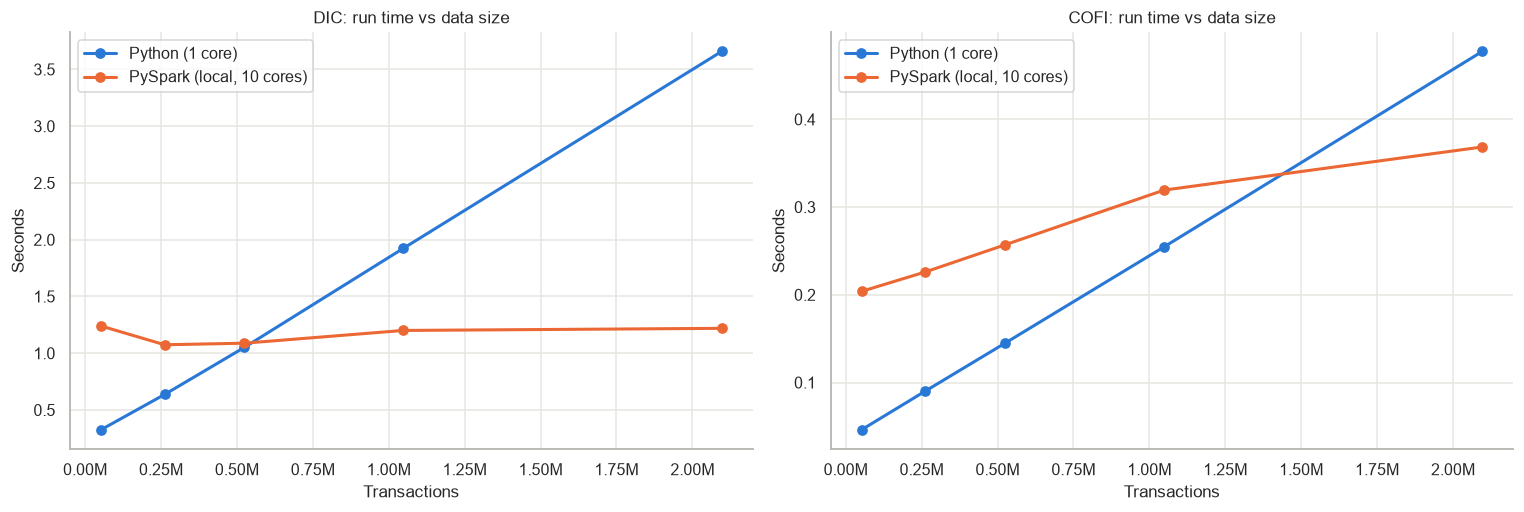

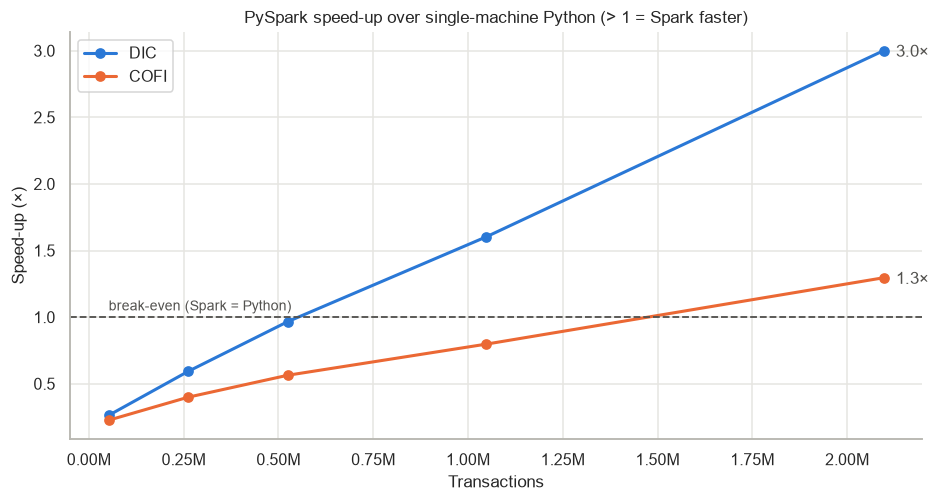

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, alg in zip(axes, ['DIC', 'COFI']):
    ax.plot(res.transactions, res[f'{alg} python'], marker='o', lw=2, color=CAT[0], label='Python (1 core)')
    ax.plot(res.transactions, res[f'{alg} spark'], marker='o', lw=2, color=CAT[1], label=f'PySpark (local, {P} cores)')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.2f}M'))
    ax.set(title=f'{alg}: run time vs data size', xlabel='Transactions', ylabel='Seconds')
    ax.legend(loc='upper left')
fig.tight_layout(); save_fig('35_spark_runtime_vs_size'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.8))
for alg, c in [('DIC', CAT[0]), ('COFI', CAT[1])]:
    ax.plot(res.transactions, res[f'{alg} speed-up'], marker='o', lw=2, color=c, label=alg)
    ax.annotate(f"{res[f'{alg} speed-up'].iloc[-1]:.1f}×", (res.transactions.iloc[-1], res[f'{alg} speed-up'].iloc[-1]),
                textcoords='offset points', xytext=(8, -4), color='#52514e')
ax.axhline(1, color='#52514e', ls='--', lw=1.2); ax.text(res.transactions.iloc[0], 1.05, 'break-even (Spark = Python)', color='#52514e', fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.2f}M'))
ax.set(title='PySpark speed-up over single-machine Python (> 1 = Spark faster)', xlabel='Transactions', ylabel='Speed-up (×)')
ax.legend(loc='upper left')
save_fig('36_spark_speedup_vs_size'); plt.show()

**Inferences:**
- **Correct at every scale:** all counts equal *k × base* from 52 k to 2.1 M transactions.
- **DIC:** Python time grows linearly (0.33 s → 3.66 s); **Spark stays flat at ≈ 1.2 s**. Break-even ≈ **0.55 M transactions**; at 2.1 M Spark is **3.0× faster**. Spark's DIC time is almost all fixed cost (≈ 55 stations × one Spark job each); the counting itself is spread over 10 cores.
- **COFI:** both versions first merge identical transactions, so only that one pass grows with data; mining always runs on the same 3,986 distinct transactions. Python: 0.05 s → 0.48 s; **Spark: 0.20 s → 0.37 s**, because the merge pass is split over 10 cores. Break-even ≈ **1.5 M transactions**; at 2.1 M Spark is **1.30× faster**.
- **Each extra million rows costs** Python 1.65 s (DIC) / 0.21 s (COFI) but Spark only 0.08 s / 0.08 s → the speed-up keeps growing with data (Gustafson's law).
- Caveat: replicated data is full of duplicates, which favours the merge step. The real data already shrinks 13× (52,416 → 3,986), so the merge helps there too, but less than at 40×.

## 4. Where the COFI gain comes from — naive vs combiner
Same 2.1 M transactions, 10 cores. Only the data flow differs: the naive version projects **every record** into FP-paths before any merging; the combiner version first merges identical transactions inside each partition (OS/DBMS idea: aggregate *before* moving data).

In [6]:
K = SCALES[-1]; Tk = T_ids * K
F1 = {next(iter(s)) for s in f_py_cofi if len(s) == 1}
trdd = sc.parallelize(Tk, 2 * P).cache(); trdd.count()
(f_n, _), t_naive = best_of(lambda: spark_cofi_naive(sc, trdd, MIN_SUP))
(f_c, st), t_comb = best_of(lambda: spark_cofi(sc, trdd, MIN_SUP))
local_distinct = trdd.mapPartitions(lambda it: [len({tuple(sorted(t)) for t in it})]).sum()
trdd.unpersist()
W = {}
for t in Tk[:N0]: W[tuple(sorted(t))] = 1
paths = lambda ts: sum(sum(i in F1 for i in t) for t in ts)
t_py = res['COFI python'].iloc[-1]
abl = pd.DataFrame({
    'version': ['naive (per record)', 'combiner (per distinct transaction)'],
    'Spark jobs': [3, 2],                                                 # naive: count, supports, mine
    'rows after map-side merge': [len(Tk), local_distinct],
    'FP-path records projected': [paths(Tk), paths(W)],
    'time (s)': [t_naive, t_comb],
    'speed-up vs single-machine': [t_py / t_naive, t_py / t_comb]}).set_index('version')
print(f'Identical output: {f_n == f_c == {s: c * K for s, c in f_py_cofi.items()}} | '
      f'{st["distinct_transactions"]:,} distinct transactions out of {len(Tk):,}')
abl.to_csv(OUTPUTS / 'spark_cofi_ablation.csv')
abl.round(2)

Identical output: True | 3,986 distinct transactions out of 2,096,640


,Spark jobs,rows after map-side merge,FP-path records projected,time (s),speed-up vs single-machine
version,,,,,
naive (per record),3,2096640,22976640,2.54,0.19
combiner (per distinct transaction),2,79720,43508,0.38,1.25


**Inferences:**
- Same output, same cores, same data: changing only the **data flow** makes Spark COFI **6.7× faster** (2.54 s → 0.38 s), and turns a 0.19× slowdown into a 1.25× speed-up over the single machine.
- **Map-side combiner** (MapReduce) = **partial aggregation before the shuffle** (DBMS): each partition merges its identical transactions first, so 2.1 M rows become 79,720 and the FP-path records fall from 22,976,640 to 43,508 (528× fewer objects to create, pickle and move).
- **One fewer Spark job:** N and the item supports come from the merged data on the driver, instead of separate `count()` and support jobs (each job = a scheduling round-trip).
- Lesson: on Spark the cost was **per-record data movement, not the mining**. The naive version made Spark lose; the combiner is what establishes the gain.

## 5. Parallel scaling — same data, more cores
Fixed data size (40×, 2.1 M transactions); Spark restarted with 1, 2, 4 and 10 cores. This isolates the gain from **parallelism** itself.

 1 cores: DIC   2.93s | COFI   1.39s


 2 cores: DIC   1.73s | COFI   0.79s


 4 cores: DIC   1.40s | COFI   0.45s


10 cores: DIC   1.21s | COFI   0.36s


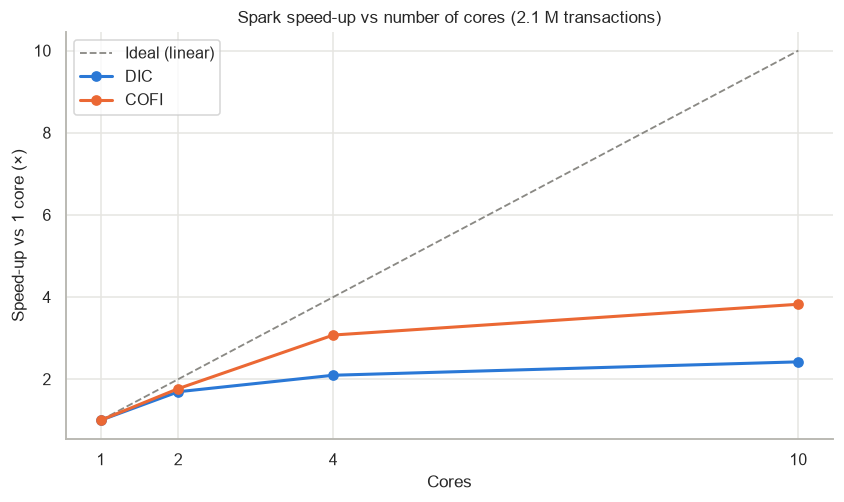

,DIC spark,COFI spark,DIC speed-up vs 1 core,COFI speed-up vs 1 core
cores,,,,
1,2.93,1.39,1.00,1.00
2,1.73,0.79,1.69,1.77
4,1.40,0.45,2.09,3.07
10,1.21,0.36,2.42,3.82


In [7]:
K = SCALES[-1]
Xk, Tk, Mk = np.tile(X, (K, 1)), T_ids * K, M0 * K
spark.stop()
core_rows = []
for cores in [1, 2, 4, 10]:
    spark, _ = start_spark(cores); sc = spark.sparkContext
    rdd, _ = masks_rdd(sc, Xk, Mk, P)                                     # same partition layout for every run
    _, t_d = best_of(lambda: spark_dic(sc, rdd, len(Xk), I, MIN_SUP, Mk, P))
    rdd.unpersist()
    trdd = sc.parallelize(Tk, 2 * P).cache(); trdd.count()
    _, t_c = best_of(lambda: spark_cofi(sc, trdd, MIN_SUP))
    trdd.unpersist(); spark.stop()
    core_rows.append({'cores': cores, 'DIC spark': t_d, 'COFI spark': t_c})
    print(f'{cores:>2} cores: DIC {t_d:6.2f}s | COFI {t_c:6.2f}s')
cores_df = pd.DataFrame(core_rows).set_index('cores')
for alg in ['DIC', 'COFI']:
    cores_df[f'{alg} speed-up vs 1 core'] = cores_df[f'{alg} spark'].iloc[0] / cores_df[f'{alg} spark']
cores_df.to_csv(OUTPUTS / 'spark_core_scaling.csv')

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cores_df.index, cores_df.index, ls='--', color='#8a8984', lw=1.2, label='Ideal (linear)')
for alg, c in [('DIC', CAT[0]), ('COFI', CAT[1])]:
    ax.plot(cores_df.index, cores_df[f'{alg} speed-up vs 1 core'], marker='o', lw=2, color=c, label=alg)
ax.set(title=f'Spark speed-up vs number of cores ({len(Xk)/1e6:.1f} M transactions)', xlabel='Cores', ylabel='Speed-up vs 1 core (×)',
       xticks=cores_df.index)
ax.legend(loc='upper left')
save_fig('37_spark_speedup_vs_cores'); plt.show()
cores_df.round(2)

**Inferences (fixed 2.1 M transactions):**
- **COFI: 3.8× on 10 cores** (1.39 s → 0.36 s); **DIC: 2.4×** (2.93 s → 1.21 s).
- Both are below linear — **Amdahl's law**. Solving *S = 1 / (f + (1 − f)/p)* for the serial fraction gives **f ≈ 18% for COFI** (job scheduling, mining 3,986 merged transactions) and **f ≈ 35% for DIC** (driver-side state machine, one Spark job per station). Only the counting / merging part shrinks with cores.
- On 1 core, Spark COFI is 2.9× slower than plain Python (JVM ↔ Python worker serialisation). Spark's value is **scale-out**, not single-core speed.

## 6. Overheads

In [8]:
pd.DataFrame({'Spark start-up (s)': [t_start],
              'Load + cache, DIC masks at 40× (s)': [res['spark load DIC'].iloc[-1]],
              'Load + cache, COFI transactions at 40× (s)': [res['spark load COFI'].iloc[-1]]}).round(2).T.rename(columns={0: 'seconds'})

,seconds
Spark start-up (s),2.70
"Load + cache, DIC masks at 40× (s)",1.06
"Load + cache, COFI transactions at 40× (s)",0.34


**Inference:** Spark start-up (2.7 s) and loading/caching (0.3–1.1 s at 40×) are **one-off** costs. Including them, Spark DIC at 2.1 M takes ≈ 5.0 s vs 3.7 s in Python, so a single one-off run at this size does not pay off. The gain appears when a session and cached data are **reused** — e.g. re-mining at several supports or with new data — or when data no longer fits one machine.

## 7. Summary

| Aspect | DIC on PySpark | COFI on PySpark |
|---|---|---|
| Parallel design | each station's block split over 10 partitions; driver keeps DIC state machine | map-side combiner (merge identical transactions per partition), then one task per item's COFI-tree |
| Correctness | identical itemsets and counts at all scales (52 k → 2.1 M) | identical at all scales |
| Break-even vs Python | ≈ 0.55 M transactions | ≈ 1.5 M transactions |
| Speed-up at 2.1 M | **3.0×** (3.66 s → 1.22 s) | **1.30×** (0.48 s → 0.37 s); naive version 0.19× |
| Cost per extra 1 M rows | 1.65 s → 0.08 s | 0.21 s → 0.08 s |
| Speed-up from 1 → 10 cores | 2.4× (serial fraction ≈ 35%) | 3.8× (serial fraction ≈ 18%) |
| Limiting factor | fixed per-station job cost | fixed job cost after the merge |

**Performance enhancement established:** at 2.1 M transactions Spark is **3.0× faster for DIC** and **1.30× faster for COFI**, with identical results, and Spark's cost per extra million rows is a fraction of Python's, so both gains grow with data. For COFI the gain needed a **map-side combiner** (6.7× faster than the naive Spark version). The original 52 k dataset is too small for Spark: start-up and per-job costs dominate, and Spark is slower at 1×.